# D13. PEFT · LoRA Fine-tuning: 저사양 GPU로 도메인 용어 가르치기

**음성 AI 전문가 과정 (160h) | 3주차 M3 한국어 ASR Fine-tuning | 4시간**

## 학습 목표
1. **PEFT**(Parameter-Efficient Fine-Tuning)가 필요한 이유와 **LoRA**의 원리(W는 고정, 작은 B · A만 학습)를 설명할 수 있다.
2. LoRA의 **학습 파라미터 수 · 메모리**를 계산하고 Full Fine-tuning(D12)과 비교한다.
3. **도메인 용어**(의료 · 법률 · 산업)가 들어간 학습 · 시험 데이터를 만들고, **CER + 용어 정확도**로 평가한다.
4. 학습 없이 쓰는 **프롬프트(initial_prompt)** 와 **LoRA 학습**을 같은 시험 문장으로 비교한다.
5. **`peft`** 로 Whisper에 LoRA를 붙여 `Seq2SeqTrainer`로 학습하고, 원래 실력(일반 문장)이 유지되는지 확인한다.
6. **어댑터를 저장 · 불러오기 · 병합(merge)** 하고, 도메인별로 갈아 끼우는 방법을 안다.
7. (선택) **8-bit 양자화**로 더 큰 모델을 작은 GPU에 올린다.

## 오늘의 실습 흐름
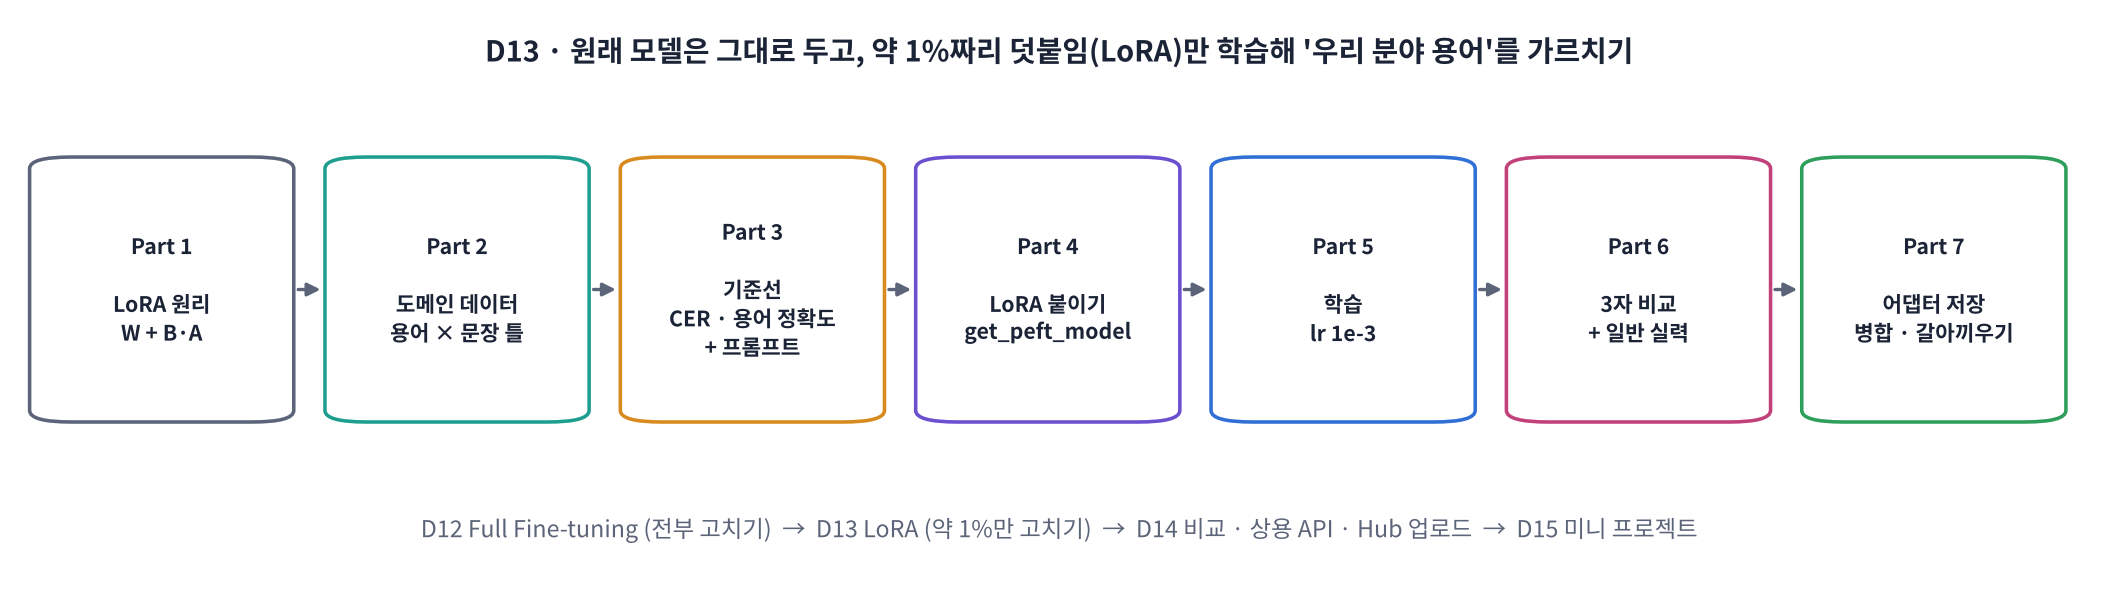

| 교시 | 내용 | 실습 |
|---|---|---|
| 1교시 | PEFT · LoRA 원리, 파라미터 · 메모리 계산, 도메인 데이터 만들기 | Part 0 ~ 2, 워크시트 1교시 |
| 2교시 | 평가 도구(CER + 용어 정확도), 기준선: 원래 모델 vs 프롬프트 | Part 3, 워크시트 2교시 |
| 3교시 | LoRA 붙이기 · **학습(T4 약 5~10분)** · 3자 비교 · 원래 실력 확인 | Part 4 ~ 6, 워크시트 3교시 |
| 4교시 | 어댑터 저장 · 병합 · 갈아 끼우기, (선택) 8-bit, 정리 | Part 7 ~ 9, 워크시트 4교시 · 노션 제출 |

## 오늘의 수업 자료
| 자료 | 링크 | 언제 쓰나요 |
|---|---|---|
| 🎬 인터랙티브 애니메이션 | [animation.html](https://imguru-mooc.github.io/AI_Voice/day13/animation.html) | 각 Part 설명을 볼 때 (Part마다 바로가기 링크가 있습니다) |
| 📝 개념 워크시트 | [worksheet.html](https://imguru-mooc.github.io/AI_Voice/day13/worksheet.html) | 각 교시 끝에 해당 탭 10문항 (4교시 × 10문항), 오답 캡처 → 노션 |

## 이 노트북 사용법
- ▶️ 일반 코드 셀은 위에서부터 차례로 실행합니다. `!`로 시작하는 줄은 리눅스 명령입니다.
- 🧩 **빈칸 실습** 셀은 `____`(밑줄 4개)를 지우고 알맞은 값을 채운 뒤 실행합니다. 마지막 줄에서 ✅ 또는 ❌로 결과를 알려줍니다. 🔑 **정답 및 해설 보기**를 클릭하면 정답이 펼쳐집니다.

| 표시 | 뜻 |
|---|---|
| 💬 **쉽게 말하면** | 그 절의 내용을 한 문장으로 |
| 🍎 **비유** | 일상의 장면으로 바꿔 보기 |
| 👣 **한 단계씩** | 무슨 일이 어떤 순서로 일어나는지 |
| 📐 **핵심 식 하나** | 꼭 기억할 식 하나 |
| ❓ **생각해 보기** | 스스로 답해 보고 펼쳐서 확인 |
| 🔍 **코드 해설** | 주요 코드를 한 줄씩 |

> ⚙️ **[런타임] → [런타임 유형 변경] → T4 GPU** 를 먼저 고르세요. GPU가 없으면 자동으로 **맛보기 모드**(whisper-tiny · 아주 짧은 학습)가 됩니다.
>
> 🏥 0-1의 `CFG["domain"]`에서 **의료 · 법률 · 산업** 중 하나를 고릅니다. 옆 사람과 다른 도메인을 고르면 4교시에 결과를 비교하기 좋습니다.

> 🎬 **애니메이션 D13-1:** [오늘의 흐름](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#flow) — Part 1~7 로드맵

## Part 0. 준비

> 🛠️ **버전 충돌 방지 (D8 · D11 · D12와 같은 방식)**: Colab에 미리 깔린 `torch` · `transformers` · `accelerate` · `datasets` 등의 버전을 **그대로 고정**한 채 `peft`(LoRA 라이브러리)를 추가합니다. `gTTS`는 `click<8.2` 요구 때문에 **의존성 없이(`--no-deps`)** 설치합니다(D8에서 겪은 문제).

In [ ]:
# 📦 설치: Colab 기본 패키지 버전은 그대로 고정하고 필요한 것만 추가 (런타임 재시작 불필요)
import importlib.metadata as md
KEEP = ["torch", "torchaudio", "torchvision", "transformers", "tokenizers", "huggingface-hub",
        "datasets", "accelerate", "click", "numpy", "protobuf"]
pins = []
for p in KEEP:
    try:
        pins.append(f"{p}=={md.version(p)}")
    except md.PackageNotFoundError:
        pass
open("colab_constraints.txt", "w").write("\n".join(pins) + "\n")
print("고정한 버전:", ", ".join(pins))

!pip install -q -c colab_constraints.txt peft datasets accelerate jiwer soundfile librosa requests
!pip install -q --no-deps gTTS        # gTTS의 click<8.2 요구가 huggingface_hub를 끌어내리지 않도록
print("✅ 설치 완료")

In [ ]:
import os, io, re, time, random, hashlib
import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import torch
import jiwer
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from gtts import gTTS

SR = 16000
random.seed(0); np.random.seed(0); torch.manual_seed(0)

def check(cond, hint="빈칸을 다시 확인하세요."):
    print("✅ 정답입니다! 🎉" if cond else f"❌ {hint}")

import importlib.metadata as md
print(" · ".join(f"{p} {md.version(p)}" for p in ["torch", "transformers", "peft", "accelerate", "datasets"]))
GPU = torch.cuda.is_available()
DEVICE = "cuda" if GPU else "cpu"
if GPU:
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} · 메모리 {p.total_memory / 1024**3:.1f} GB")
else:
    print("⚠️ GPU 없음 → 맛보기 모드 ([런타임] → [런타임 유형 변경] → T4 GPU 권장)")

### 0-1. 오늘의 실험 설정
`domain`을 `"의료"`, `"법률"`, `"산업"` 중 하나로 고르세요.

In [ ]:
CFG = dict(
    domain     = "의료",                                   # "의료" | "법률" | "산업"
    model_name = "openai/whisper-small" if GPU else "openai/whisper-tiny",
    n_replay   = 200 if GPU else 20,       # 원래 실력 유지용 Zeroth 일반 문장 (학습에 섞기)
    n_general  = 50  if GPU else 10,       # 원래 실력 확인용 Zeroth 시험 문장
    r          = 32,                       # LoRA rank (덧붙임 행렬의 폭)
    alpha      = 64,                       # LoRA 크기 조절 (보통 r의 2배)
    max_steps  = 200 if GPU else 12,
    batch      = 16 if GPU else 8,
    eval_steps = 50  if GPU else 6,
)
EN = {"의료": "medical", "법률": "legal", "산업": "industry"}[CFG["domain"]]
for k, v in CFG.items():
    print(f"{k:11s} = {v}")

## Part 1. PEFT · LoRA 원리: 큰 행렬은 얼리고, 작은 덧붙임만 학습

> 💬 **쉽게 말하면**: D12에서는 Whisper small의 **2.4억 개를 전부** 고쳤습니다. LoRA는 원래 가중치 W를 **얼려 두고(고정)**, 그 옆에 **아주 작은 행렬 두 개(B · A)** 를 붙여 그것만 학습합니다. 고칠 숫자가 약 1%로 줄어 **기울기 · Adam 메모리가 거의 없어지고**, 결과 파일도 **수십 MB**입니다.

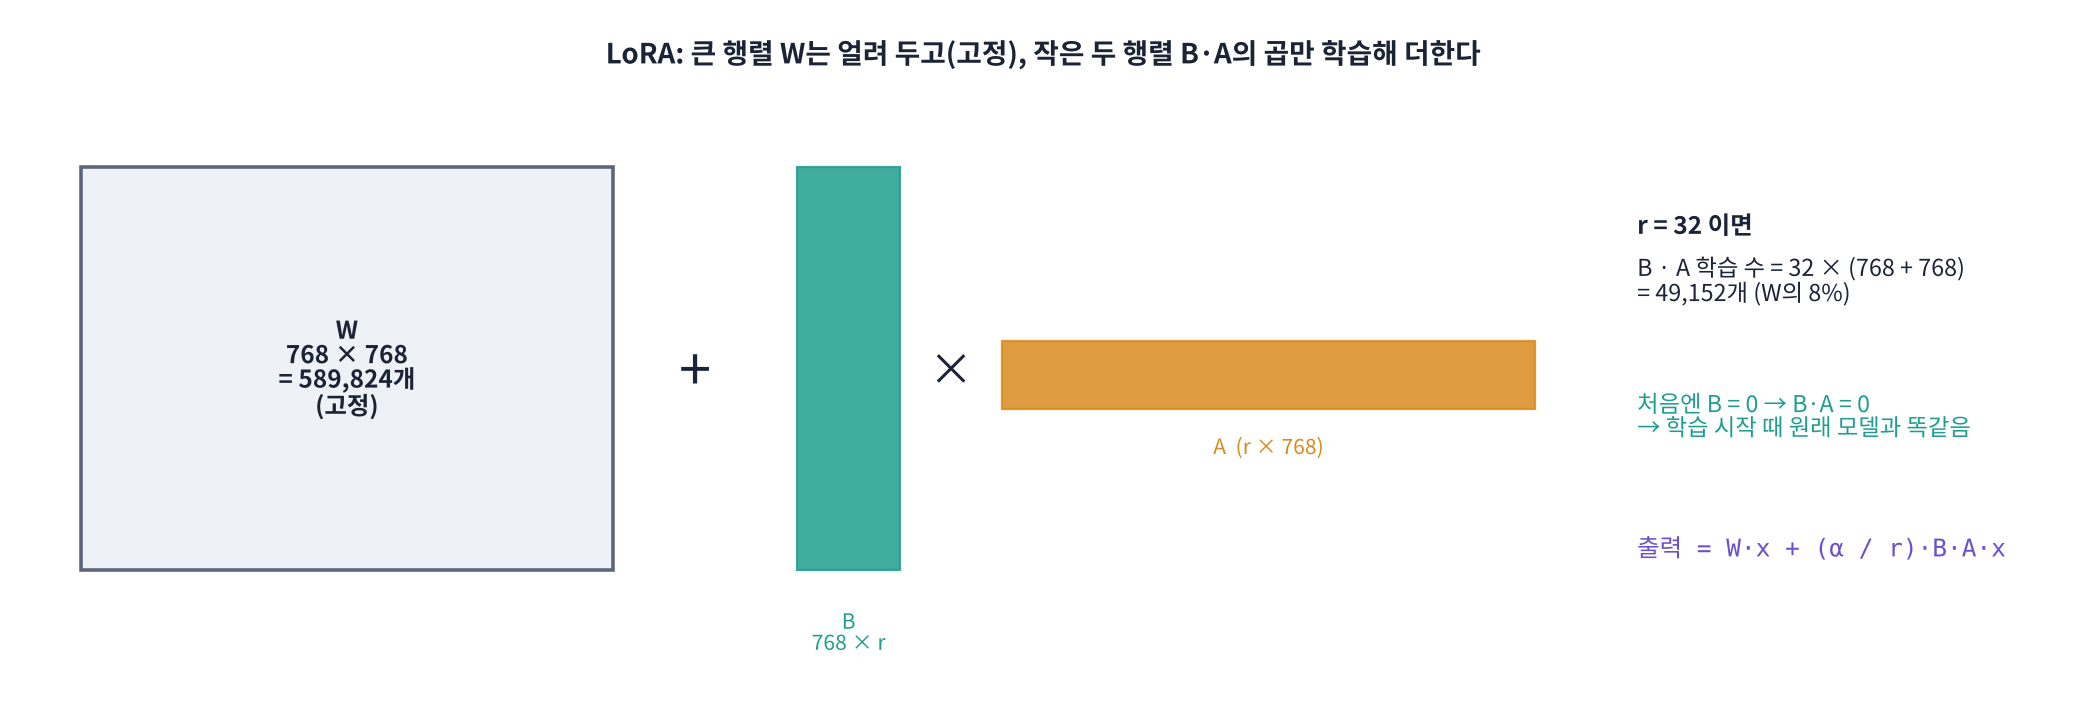

> 🍎 **비유: 교과서에 포스트잇 붙이기.** 두꺼운 교과서(W)를 다시 쓰는 대신, 고칠 곳에 **포스트잇(B · A)** 을 붙입니다. 교과서는 그대로라 다른 과목(도메인) 포스트잇으로 **갈아 붙일 수도** 있고, 마음에 들면 나중에 교과서에 **옮겨 적을(merge)** 수도 있습니다.

> 📐 **핵심 식 하나: 출력 = W·x + (α / r) · B·A·x** — W(d × d)는 고정, B(d × r) · A(r × d)만 학습. r은 보통 8~64. 처음엔 **B = 0** 이라 시작할 때는 원래 모델과 똑같습니다.

👣 **한 단계씩**
1. W는 `requires_grad=False` → 기울기 · Adam 상태가 없음 (메모리 절약의 핵심)
2. A는 작은 무작위 값, B는 0으로 시작 → B·A = 0 → 학습 첫 순간엔 원래 모델 그대로
3. 학습하면서 B · A가 '우리 분야에 필요한 작은 변화'를 배움
4. 끝나면 B · A만 저장(수십 MB). 쓸 때는 원래 모델에 붙이거나, W에 더해 합침(merge)

> 🎬 **애니메이션 D13-2:** [LoRA 행렬 놀이터](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#lora) — r을 바꾸며 학습 파라미터 수와 B·A 모양이 어떻게 바뀌는지

### 🧩 빈칸 실습 1 · 2: LoRA를 숫자로 직접 만들어 보기
whisper-small의 attention 행렬 하나(768 × 768)에 r = 32 LoRA를 붙입니다.
- 빈칸 1: A는 (r × d_in), B는 (d_out × r) → LoRA 파라미터 수 = r × (d_in + **?**)
- 빈칸 2: 학습 시작 때 B·A가 0이 되도록 B를 **모두 0** 으로 만드는 numpy 함수

In [ ]:
# 🧩 빈칸 실습 1 · 2
d_in, d_out, r, alpha = 768, 768, 32, 64
rng = np.random.default_rng(0)

W = rng.normal(0, 0.02, (d_out, d_in))                    # 원래 가중치 (고정)
A = rng.normal(0, 0.02, (r, d_in))                        # 작은 무작위 값
B = np.____((d_out, r))                                   # 빈칸 2: 처음엔 0

full_params = d_in * d_out
lora_params = r * (d_in + ____)                           # 빈칸 1
print(f"W: {full_params:,}개  ·  LoRA(A + B): {lora_params:,}개  →  {100 * lora_params / full_params:.1f}%")

x = rng.normal(0, 1, d_in)
y0 = W @ x
y_lora = W @ x + (alpha / r) * (B @ (A @ x))              # LoRA 출력
print("학습 시작 때 원래 출력과 같은가?", np.allclose(y0, y_lora))

# 학습이 B를 조금 바꿨다고 가정해 보기
B_trained = rng.normal(0, 0.01, (d_out, r))
delta = (alpha / r) * (B_trained @ A)                     # W에 더해질 변화량 ΔW
print(f"ΔW의 rank(독립인 방향 수) = {np.linalg.matrix_rank(delta)}  (최대 r = {r})")
check(lora_params == 49152 and np.allclose(y0, y_lora), hint="빈칸 1 = d_out, 빈칸 2 = zeros")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
B = np.zeros((d_out, r))
lora_params = r * (d_in + d_out)
```

**해설**: A가 r × 768, B가 768 × r이라 합치면 32 × (768 + 768) = 49,152개 = W의 **8.3%**. Whisper small 전체로 보면 q · v 행렬에만 붙이므로 약 **354만 개(전체의 1.5%)** 입니다(Part 4에서 확인). B를 0으로 두는 이유는 **학습 첫 순간 모델이 원래 Whisper와 똑같도록** 하기 위해서입니다. A까지 0이면 기울기가 0이 되어 아무것도 배우지 못하므로 A는 작은 무작위 값입니다. ΔW = B·A의 rank가 최대 r이라는 것이 'Low-Rank'라는 이름의 뜻입니다. **'큰 변화가 필요 없고, 몇 가지 방향으로만 조금 바꾸면 된다'** 는 가정입니다.

</details>

### 1-1. 얼마나 아끼나: 파라미터와 메모리

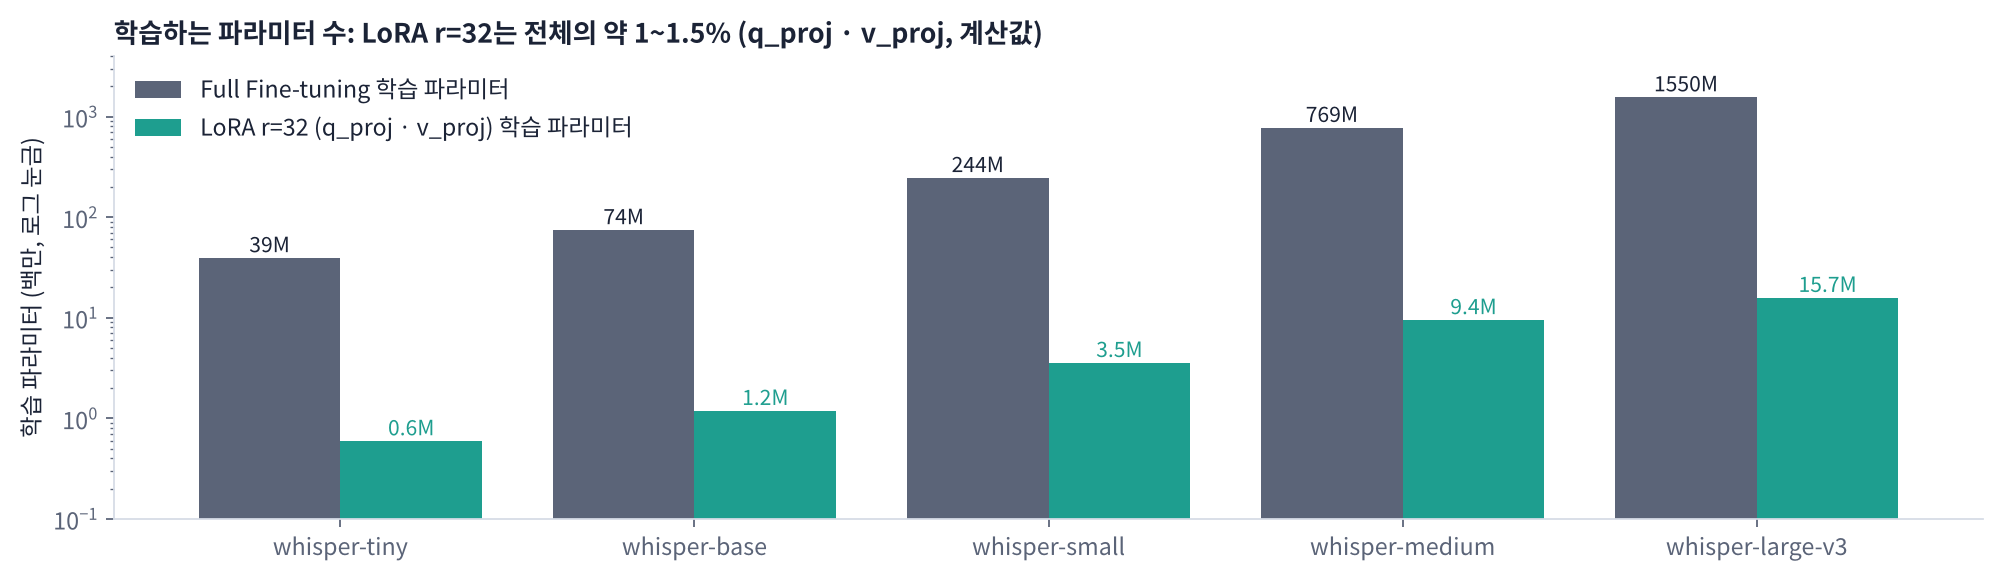

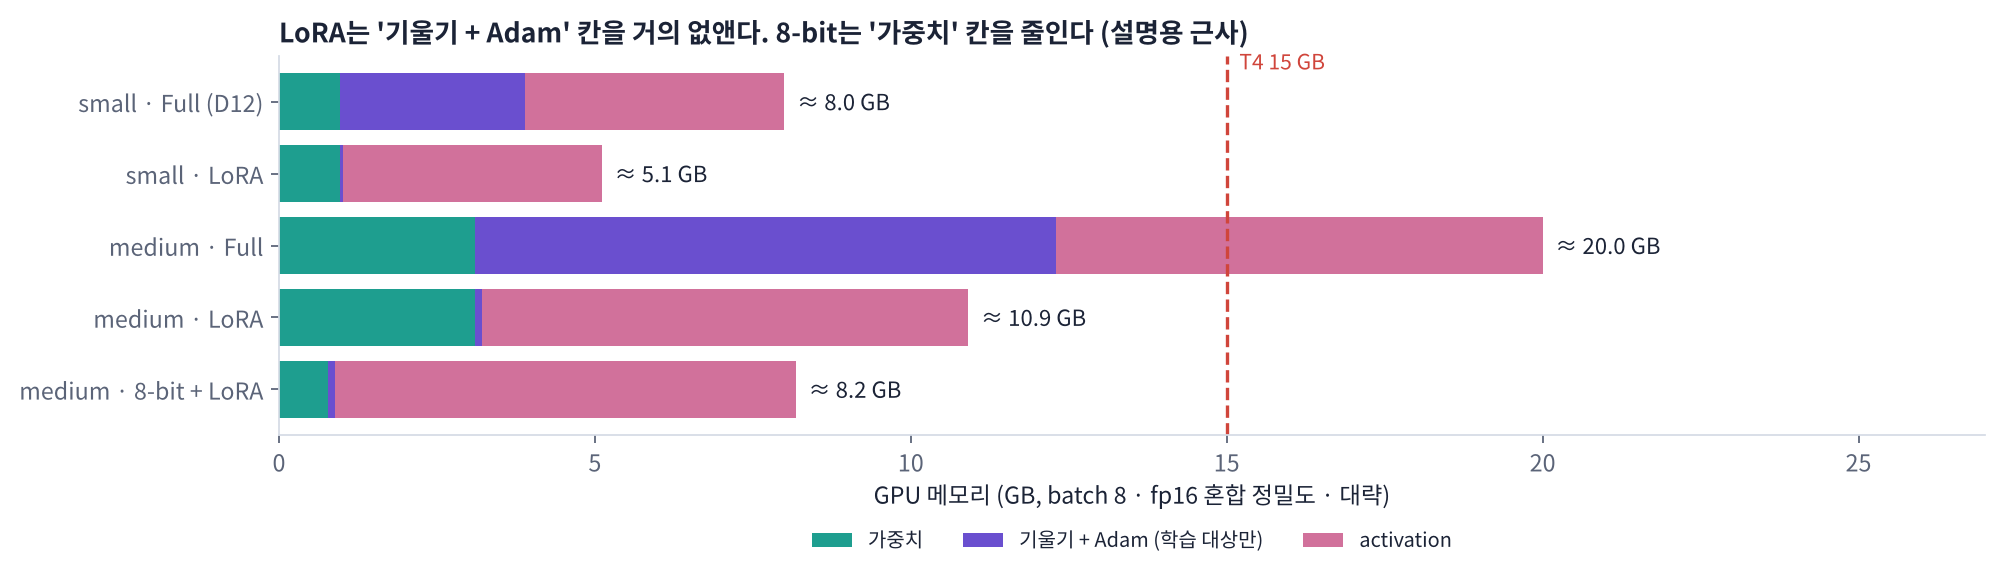

| 항목 | Full Fine-tuning (D12) | LoRA (오늘) |
|---|---|---|
| 학습 파라미터 | 2.4억 (100%) | 약 354만 (1.5%) |
| 기울기 + Adam 상태 | 파라미터 × 12바이트 ≈ 2.9 GB | ≈ 0.04 GB |
| 결과 파일 | 약 1 GB (모델 전체) | **약 14 MB** (어댑터만) |
| 학습률 | 1e-5 | **1e-3** (작은 행렬을 0부터 키우므로 크게) |

> ⚠️ **activation(중간 계산값)** 은 LoRA여도 줄지 않습니다. 소리가 모델 전체를 통과해야 하기 때문입니다. 그래서 batch를 크게 하면 여전히 메모리가 늘어납니다.

> 🎬 **애니메이션 D13-6:** [GPU 메모리 비교](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#memory) — Full · LoRA · 8-bit + LoRA를 모델 크기별로

## Part 2. 도메인 데이터 만들기: 용어 × 문장 틀

> 💬 **쉽게 말하면**: Whisper가 일상 말은 잘 받아쓰지만 **'심방세동', '근저당권', '서보모터'** 같은 전문 용어는 자주 틀립니다. 오늘은 용어 20개를 **문장 틀 10개**에 넣어 200문장을 만들고, gTTS로 읽혀 **소리 + 전사** 데이터를 만듭니다. 시험은 **학습에 쓰지 않은 문장 틀 3개**로 봅니다.

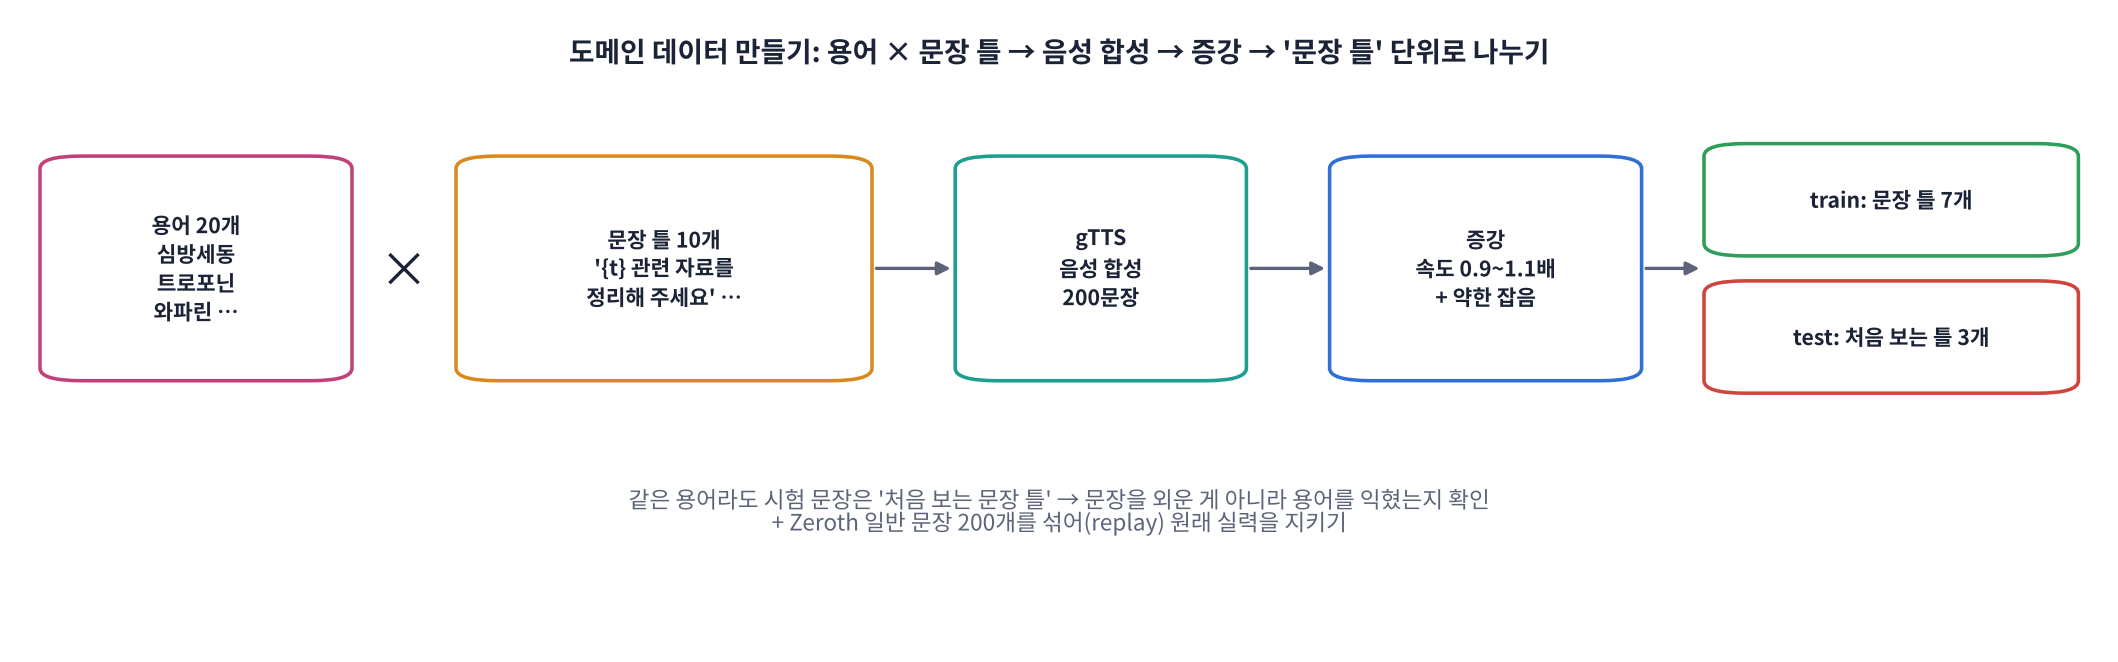

| 설계 | 이유 |
|---|---|
| 시험 = **처음 보는 문장 틀** | 문장을 통째로 외운 게 아니라 **용어 자체를 익혔는지** 확인 |
| 학습 문장마다 **증강 1개**(속도 0.9~1.1배 + 약한 잡음) | 같은 목소리 · 속도에만 맞춰지지 않게 |
| **Zeroth 일반 문장 섞기**(replay) | 용어만 배우다 원래 실력을 잊지 않게 (catastrophic forgetting 방지) |

> ⚠️ **한계**: gTTS는 **한 사람의 합성 목소리**입니다. 실제 서비스라면 **여러 사람이 녹음한 진짜 소리**로 학습 · 시험해야 합니다(과제 3). 오늘은 '용어를 가르치는 방법'을 익히는 데 집중합니다.

> 🎬 **애니메이션 D13-3:** [도메인 데이터 설계](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#domain) — 용어 · 문장 틀 · 증강 · 나누기를 바꿔 보기

In [ ]:
DOMAINS = {
    "의료": ["심방세동", "트로포닌", "와파린", "메트포르민", "아세트아미노펜", "크레아티닌", "당화혈색소", "심근경색",
             "폐색전증", "패혈증", "기관지확장제", "프레드니솔론", "혈소판감소증", "갑상선기능저하증", "신우신염", "대상포진",
             "담낭절제술", "관상동맥조영술", "항응고제", "인슐린 글라진"],
    "법률": ["소멸시효", "가압류", "근저당권", "손해배상청구", "집행유예", "기판력", "채권자대위권", "부당이득반환",
             "공탁금", "항소이유서", "가처분", "유치권", "사해행위취소", "성년후견인", "상계", "확정판결",
             "소송비용", "공시송달", "이행권고결정", "지급명령"],
    "산업": ["공압 실린더", "서보모터", "인버터 과전류", "PLC 래더", "컨베이어 벨트", "용접 비드", "사출 성형", "금형 온도",
             "진동 센서", "베어링 마모", "유압 펌프", "냉각탑", "안전 인터록", "비상 정지", "토크 렌치", "치공구",
             "공정 능력 지수", "불량률", "설비 종합 효율", "예지 정비"],
}
TEMPLATES = [                                          # 앞 7개 = 학습, 뒤 3개 = 시험 (처음 보는 틀)
    "오늘 회의에서 {t} 문제를 다시 다뤘습니다", "{t} 관련 자료를 정리해 주세요", "방금 말씀하신 {t} 부분을 다시 확인하겠습니다",
    "보고서에 {t} 항목을 추가했습니다", "{t} 때문에 일정이 조금 늦어졌습니다", "담당자에게 {t} 내용을 전달했습니다",
    "다음 주까지 {t} 검토를 마치겠습니다",
    "기록지에 {t} 항목을 표시해 주세요", "{t} 경과를 내일 다시 보겠습니다", "고객에게 {t} 설명을 드렸습니다",
]
N_TRAIN_TPL = 7
TERMS = DOMAINS[CFG["domain"]]
PROMPT = ", ".join(TERMS)                               # Part 3 프롬프트 비교용 용어 목록
print(f"도메인: {CFG['domain']} · 용어 {len(TERMS)}개 · 문장 틀 {len(TEMPLATES)}개 → {len(TERMS) * len(TEMPLATES)}문장")
print("예:", TEMPLATES[0].format(t=TERMS[0]))

In [ ]:
os.makedirs("tts_cache", exist_ok=True)

def tts(text, tries=3):                                 # 같은 문장은 한 번만 합성 (캐시)
    path = f"tts_cache/{hashlib.md5(text.encode()).hexdigest()}.mp3"
    for k in range(tries):
        try:
            if not os.path.exists(path):
                gTTS(text, lang="ko").save(path)
            break
        except Exception as e:                          # 너무 빨리 많이 부르면 잠깐 막힐 수 있음
            print("gTTS 재시도:", e); time.sleep(3 * (k + 1))
    y, _ = librosa.load(path, sr=SR, mono=True)
    y, _ = librosa.effects.trim(y, top_db=35)
    return y.astype(np.float32)

def augment(y, rng):                                    # 속도 0.9~1.1배 + SNR 약 20 dB 잡음
    y2 = librosa.effects.time_stretch(y, rate=rng.uniform(0.9, 1.1))
    noise = rng.normal(0, 1, len(y2)) * np.sqrt(np.mean(y2 ** 2)) / 10
    return (y2 + noise).astype(np.float32)

rng = np.random.default_rng(0)
t0 = time.time()
dom_train, dom_test = [], []
for ti, tpl in enumerate(TEMPLATES):
    for term in TERMS:
        text = tpl.format(t=term)
        y = tts(text)
        row = dict(audio=y, text=text, term=term)
        if ti < N_TRAIN_TPL:
            dom_train += [row, dict(row, audio=augment(y, rng))]
        else:
            dom_test.append(row)
print(f"도메인 학습 {len(dom_train)}개 (원본 + 증강) · 시험 {len(dom_test)}개 · {time.time() - t0:.0f}초")
display(Audio(dom_test[0]["audio"], rate=SR)); print("시험 예:", dom_test[0]["text"])

### 2-1. 원래 실력 지키기: Zeroth 일반 문장 (D12와 같은 방법)

In [ ]:
from datasets import load_dataset, Audio as HFAudio, Dataset

def read_audio(ex):
    y, sr = sf.read(io.BytesIO(ex["audio"]["bytes"]), dtype="float32")
    if y.ndim > 1:
        y = y.mean(axis=1)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
    return y.astype(np.float32)

def take(rows_iter, n):
    out = []
    for ex in rows_iter:
        y = read_audio(ex)
        if ex["text"].strip() and len(y) / SR <= 30:
            out.append(dict(audio=y, text=ex["text"].strip(), term=None))
        if len(out) >= n:
            break
    return out

stream = load_dataset("kresnik/zeroth_korean", split="train", streaming=True).cast_column("audio", HFAudio(decode=False))
replay = take(stream, CFG["n_replay"])
zt = load_dataset("kresnik/zeroth_korean", split="test").cast_column("audio", HFAudio(decode=False))
general_test = take(zt.shuffle(seed=0), CFG["n_general"])
print(f"replay(학습에 섞기) {len(replay)}개 · 일반 시험 {len(general_test)}개")

---
### 📝 1교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 1교시 탭](https://imguru-mooc.github.io/AI_Voice/day13/worksheet.html)** — PEFT가 필요한 이유, LoRA 식(W + B·A), rank r · alpha, B = 0 초기화, 학습 파라미터 · 메모리 계산, activation은 줄지 않음, 도메인 데이터 설계(문장 틀 단위 분할 · 증강 · replay)
>
> 10문항을 풀고 **채점하기**를 누르세요. 채점 후에는 답이 잠깁니다. 제출은 4교시까지 모두 마친 뒤 한 번에 합니다.

## Part 3. 평가 도구와 기준선: 원래 모델 vs 프롬프트

> 💬 **쉽게 말하면**: 도메인 모델은 **CER만으로는 부족**합니다. 문장 대부분을 맞혀도 **핵심 용어 하나를 틀리면** 쓸모가 없기 때문입니다. 그래서 **용어 정확도**(시험 문장의 용어가 결과에 그대로 들어 있는 비율)를 함께 잽니다. 그리고 학습 없이 **용어 목록을 프롬프트로 주는 방법**(D7 initial_prompt)도 기준선으로 재 봅니다.

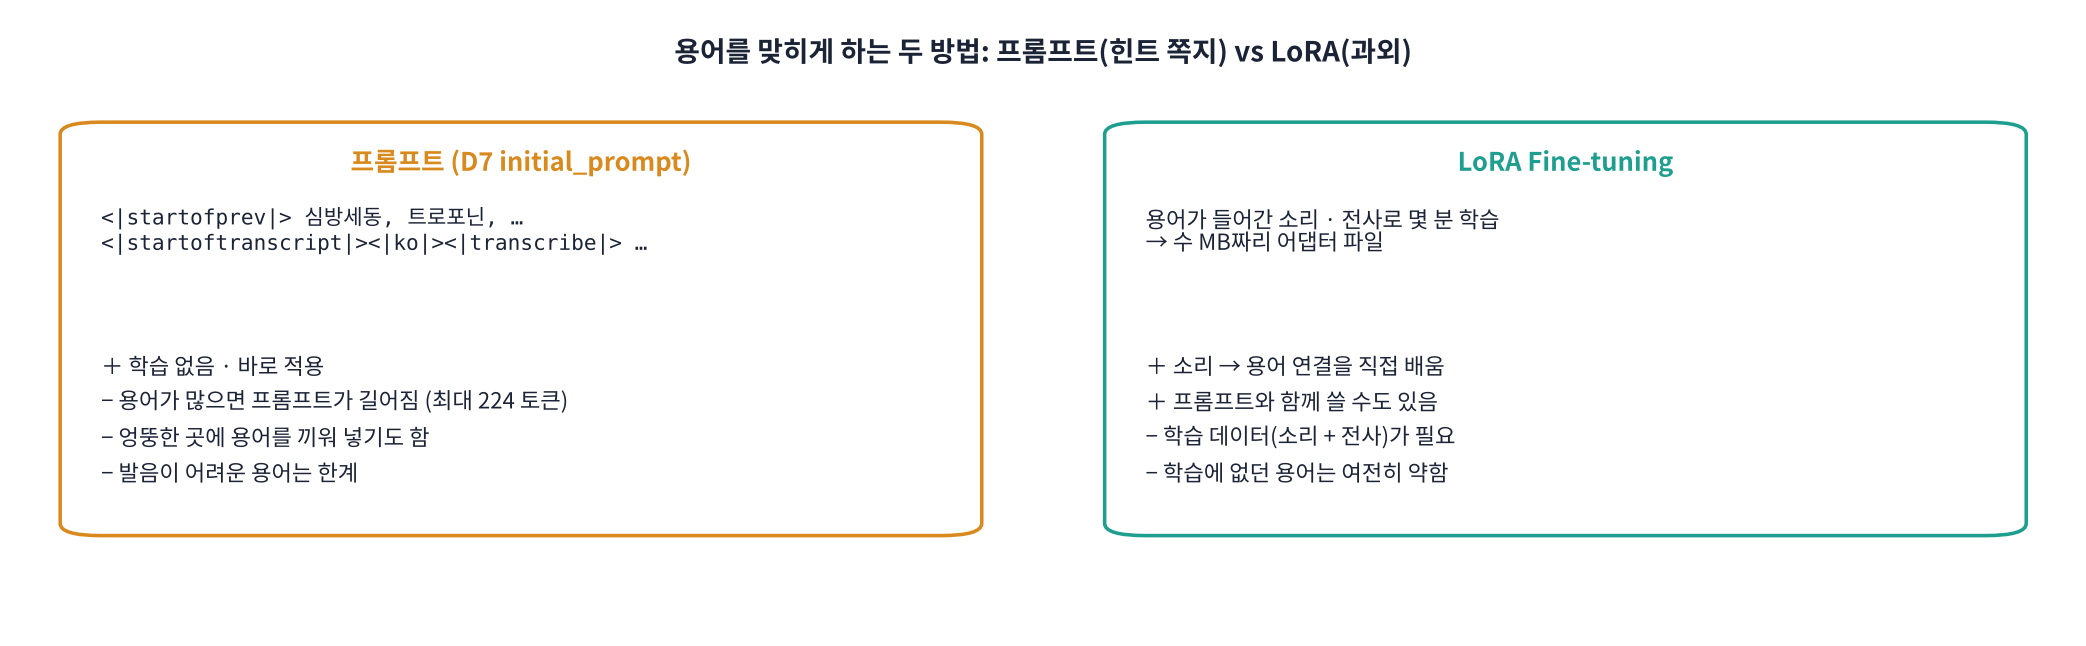

> 🎬 **애니메이션 D13-4:** [프롬프트 vs LoRA](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#prompt) — 같은 문장을 두 방법으로 받아쓰면 어떻게 다른지

### 🧩 빈칸 실습 3: 용어 정확도
각 시험 문장의 용어(`terms`)가 **받아쓴 결과(예측 목록)** 에 들어 있는지 확인합니다. 짝지을 **예측 목록 변수 이름**을 넣으세요. 띄어쓰기 차이는 `normalize()`가 없애 줍니다.

In [ ]:
# 🧩 빈칸 실습 3
def normalize(s):                                       # D10 · D12와 같은 정규화: 문장 부호 · 띄어쓰기 무시
    s = re.sub(r"[^\w\s]", "", s.lower())
    return re.sub(r"\s+", "", s)

def term_accuracy(terms, preds):
    hits = [normalize(t) in normalize(p) for t, p in zip(terms, ____)]                   # 빈칸 3
    return 100 * float(np.mean(hits))

def cer(rows, preds):
    return 100 * jiwer.cer([normalize(r["text"]) for r in rows], [normalize(p) or "∅" for p in preds])

demo_terms = ["심방세동", "와파린", "공압 실린더"]
demo_preds = ["기록에 심방 세동이라고 적어 주세요", "와파린 경과를 내일 다시 보겠습니다", "고객에게 공압실린다 설명을 드렸습니다"]
print("용어 정확도 예시:", round(term_accuracy(demo_terms, demo_preds), 1), "%  (3개 중 2개)")
check(abs(term_accuracy(demo_terms, demo_preds) - 66.67) < 0.1, hint="빈칸 3 = preds")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
hits = [normalize(t) in normalize(p) for t, p in zip(terms, preds)]
```

**해설**: '심방 세동'은 띄어쓰기만 달라 정규화하면 '심방세동'과 같아 **맞음**, '공압실린다'는 글자가 틀려 **틀림**입니다. 용어 정확도는 **엄격한 지표**입니다. 글자 하나만 틀려도 0점이라, 의료 · 법률처럼 용어가 중요한 곳에 맞습니다. 반대로 문장 전체 품질은 CER로 함께 봅니다.

</details>

### 3-1. 모델 불러오기와 받아쓰기 함수
여러 문장을 16개씩 묶어 받아씁니다. `prompt_ids`를 주면 **용어 목록을 힌트로** 앞에 붙입니다(D7).

In [ ]:
from transformers import WhisperProcessor, WhisperForConditionalGeneration

processor = WhisperProcessor.from_pretrained(CFG["model_name"], language="korean", task="transcribe")
model = WhisperForConditionalGeneration.from_pretrained(CFG["model_name"]).to(DEVICE)
model.generation_config.language = "korean"
model.generation_config.task = "transcribe"
model.accepts_loss_kwargs = False                       # D12 ⚠️: accum 때 loss 평균 보장 (오늘은 accum 1이라 영향 없음)

def transcribe(m, rows, prompt_ids=None, bs=16):
    m.eval(); out = []
    for i in range(0, len(rows), bs):
        chunk = rows[i:i + bs]
        feats = processor.feature_extractor([r["audio"] for r in chunk], sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
        kw = dict(language="korean", task="transcribe", max_new_tokens=128)
        if prompt_ids is not None:
            kw["prompt_ids"] = prompt_ids.to(DEVICE)
        with torch.no_grad():
            ids = m.generate(input_features=feats, **kw)
        out += [t.strip() for t in processor.batch_decode(ids, skip_special_tokens=True)]
    return out

test_terms = [r["term"] for r in dom_test]
t0 = time.time()
pred_base = transcribe(model, dom_test)
gen_base = transcribe(model, general_test)
RESULTS = {"① 원래 모델": dict(dom_cer=cer(dom_test, pred_base), term_acc=term_accuracy(test_terms, pred_base), gen_cer=cer(general_test, gen_base))}
print(RESULTS["① 원래 모델"], f"({time.time() - t0:.0f}초)")
for r, p in list(zip(dom_test, pred_base))[:5]:
    print(f"  정답: {r['text']}\n  결과: {p}\n")

### 🧩 빈칸 실습 4: 프롬프트로 용어 힌트 주기
`processor.get_prompt_ids()`에 **용어 목록 문자열**(Part 2에서 만든 변수)을 넣으세요. Whisper는 이것을 '앞 문장'처럼 보고 비슷한 단어를 쓰려고 합니다.

In [ ]:
# 🧩 빈칸 실습 4
prompt_ids = processor.get_prompt_ids(____, return_tensors="pt")                       # 빈칸 4
print(f"프롬프트 토큰 {len(prompt_ids)}개 (최대 약 224)")

pred_prompt = transcribe(model, dom_test, prompt_ids=prompt_ids)
gen_prompt = transcribe(model, general_test, prompt_ids=prompt_ids)
RESULTS["② 원래 모델 + 프롬프트"] = dict(dom_cer=cer(dom_test, pred_prompt), term_acc=term_accuracy(test_terms, pred_prompt), gen_cer=cer(general_test, gen_prompt))
display(pd.DataFrame(RESULTS).T.round(1))
check(len(prompt_ids) > len(TERMS) and "② 원래 모델 + 프롬프트" in RESULTS, hint="빈칸 4 = PROMPT")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
prompt_ids = processor.get_prompt_ids(PROMPT, return_tensors="pt")
```

**해설**: 프롬프트는 `<|startofprev|>` 뒤에 붙어 Whisper에게 '앞에서 이런 단어들이 나왔다'는 힌트를 줍니다. **학습 없이** 용어 정확도가 오르는 경우가 많지만, ① 용어가 많으면 프롬프트가 길어지고(최대 약 224 토큰), ② 일반 문장에도 같은 프롬프트를 주면 **엉뚱한 용어를 끼워 넣는 부작용**이 생길 수 있습니다(표의 일반 CER 확인). ③ 발음 자체를 처음 듣는 용어는 힌트만으로 한계가 있습니다.

</details>

**❓ 생각해 보기**: 프롬프트만으로 충분하다면 굳이 학습(LoRA)을 할 필요가 있을까요?

<details>
<summary>답 보기</summary>

용어가 **수십 개 이하**이고 발음이 평범하다면 프롬프트가 가장 싸고 빠른 해결책입니다. 하지만 ① 용어가 **수백 · 수천 개**(의약품 목록 등)면 프롬프트에 다 넣을 수 없고, ② **소리를 처음 듣는 단어**(외래어 약품명, 약어)는 힌트만으로 못 맞히며, ③ 말투 · 녹음 환경까지 바꿔야 하면 학습이 필요합니다. 실무에서는 **둘을 함께**(LoRA + 프롬프트) 쓰기도 합니다. Part 6에서 네 가지를 모두 비교합니다.

</details>

---
### 📝 2교시 마무리: 개념 워크시트

> **[worksheet.html 열기 → 2교시 탭](https://imguru-mooc.github.io/AI_Voice/day13/worksheet.html)** — 용어 정확도와 CER, 정규화, 문장 틀 단위 시험, initial_prompt와 get_prompt_ids, `<|startofprev|>`, 프롬프트의 장단점, 기준선을 먼저 재는 이유
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 4. Whisper에 LoRA 붙이기 (`peft`)

> 💬 **쉽게 말하면**: `LoraConfig`로 **어디에(target_modules) · 얼마나 크게(r, alpha)** 붙일지 정하고, `get_peft_model()` 한 줄로 붙입니다. 그러면 원래 가중치는 자동으로 얼려지고 LoRA 행렬만 학습 대상이 됩니다.

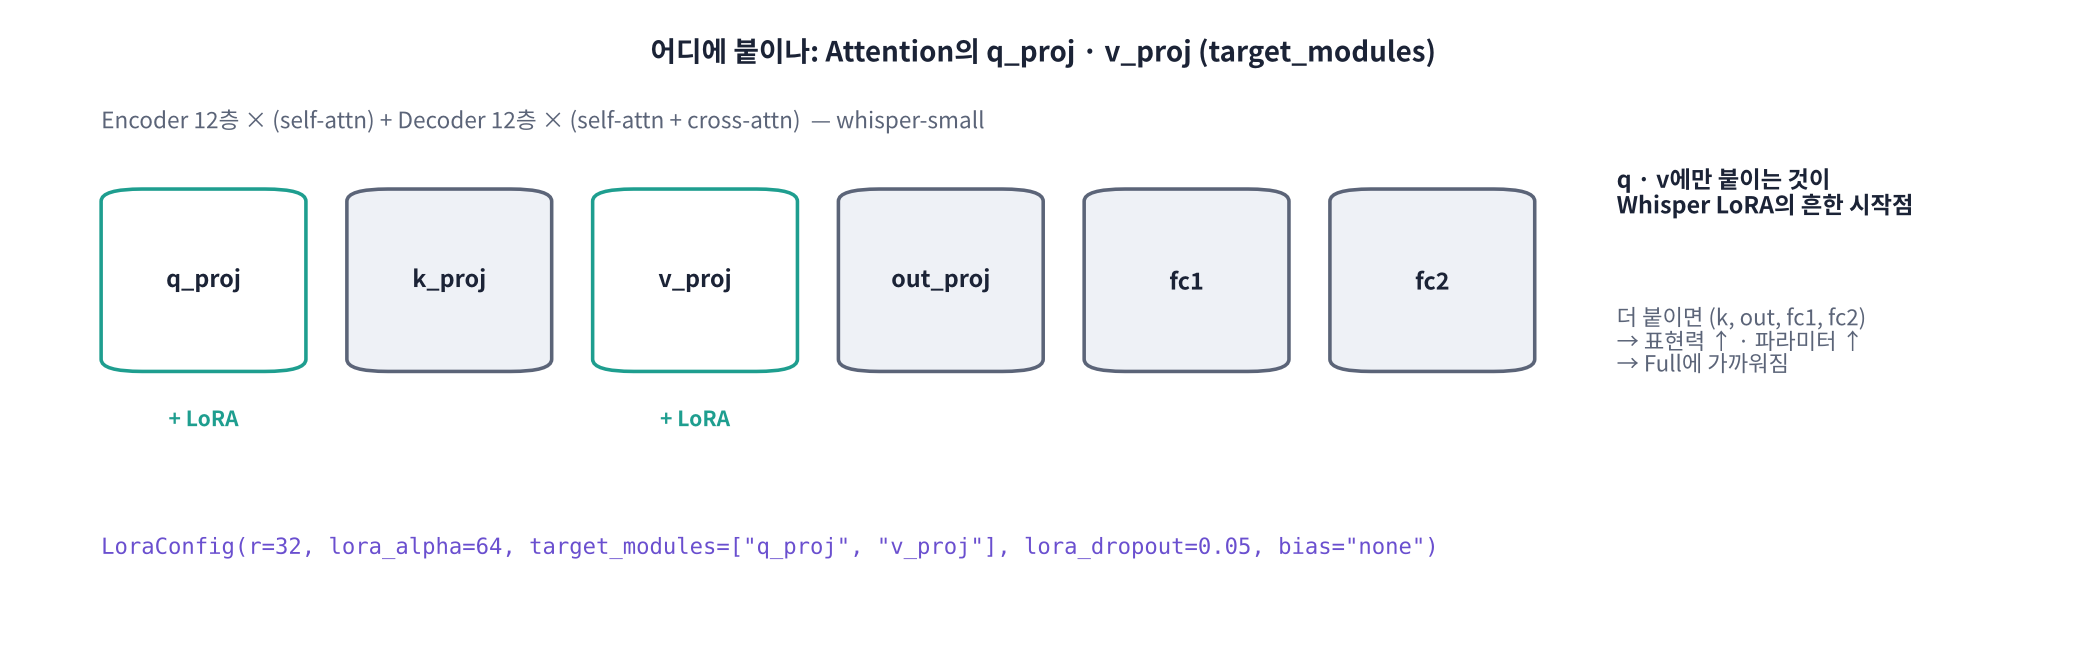

| 설정 | 오늘 값 | 뜻 |
|---|---|---|
| `r` | 32 | 덧붙임 행렬의 폭. 클수록 표현력 ↑ · 파라미터 ↑ |
| `lora_alpha` | 64 | 덧붙임 크기 조절 (실제 배율 = alpha / r = 2) |
| `target_modules` | `q_proj`, `v_proj` | attention의 query · value 행렬에 붙임 |
| `lora_dropout` | 0.05 | 덧붙임에만 약한 dropout (과적합 방지) |
| `bias` | `"none"` | bias는 학습하지 않음 |

> 🎬 **애니메이션 D13-5:** [어디에 붙일까](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#targets) — target_modules를 바꾸며 학습 파라미터 비교

### 🧩 빈칸 실습 5 · 6: LoRA 붙이기
- 빈칸 5: query와 함께 붙일 **value 행렬의 이름** (Whisper 안의 모듈 이름)
- 빈칸 6: 모델과 설정을 받아 LoRA를 붙여 주는 **peft 함수 이름**

In [ ]:
# 🧩 빈칸 실습 5 · 6
from peft import LoraConfig, get_peft_model

names = sorted({n.split(".")[-1] for n, _ in model.named_modules() if n.endswith("_proj")})
print("Whisper 안의 *_proj 모듈:", names)

lora_cfg = LoraConfig(r=CFG["r"], lora_alpha=CFG["alpha"], lora_dropout=0.05, bias="none",
                      target_modules=["q_proj", ____])                                   # 빈칸 5
total_before = sum(p.numel() for p in model.parameters())
model = ____(model, lora_cfg)                                                            # 빈칸 6
model.print_trainable_parameters()

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
gb = lambda n_bytes: n_bytes / 1024**3
print(f"\n대략 메모리 (가중치 · 기울기 · Adam, activation 제외)")
print(f"  Full : {gb(total_before * 4 + total_before * 12):.2f} GB")
print(f"  LoRA : {gb(total_before * 4 + trainable * 12):.2f} GB   (학습 대상 {trainable / 1e6:.2f}M)")
check(type(model).__name__.startswith("PeftModel") and 0 < trainable < 0.05 * total_before,
      hint='빈칸 5 = "v_proj", 빈칸 6 = get_peft_model')

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
target_modules=["q_proj", "v_proj"]
model = get_peft_model(model, lora_cfg)
```

**해설**: 출력 예(whisper-small): `trainable params: 3,538,944 || all params: 약 2.45억 || trainable%: 약 1.44`. Encoder self-attention 12층 × 2 + Decoder self · cross-attention 12층 × 4 = **72개 행렬**에 각각 32 × (768 + 768)개가 붙습니다. 원래 가중치는 `requires_grad=False`로 바뀌어 기울기 · Adam 상태가 없습니다. `k_proj` · `out_proj` · `fc1` · `fc2`까지 붙이면 파라미터가 늘고 Full에 가까워집니다. 원래 모델 객체에 LoRA 층이 **끼워 넣어지므로**, 이후 원래 모델 결과가 필요하면 `with model.disable_adapter():`를 씁니다(Part 6).

</details>

## Part 5. LoRA 학습

> 💬 **쉽게 말하면**: D12와 같은 Collator · Trainer를 그대로 씁니다. 바뀌는 것은 **학습률(1e-3, 약 100배)** 과 **데이터**(도메인 문장 + 일반 문장)뿐입니다. LoRA는 0에서 시작하는 작은 행렬을 키워야 하므로 학습률을 크게 씁니다.

| 설정 | D12 Full | D13 LoRA |
|---|---|---|
| `learning_rate` | 1e-5 | **1e-3** |
| batch × accum | 8 × 2 | 16 × 1 (메모리 여유) |
| `max_steps` | 300 | 200 |
| 데이터 | Zeroth 2,000 | 도메인 280 + Zeroth 200 |
| `label_names` | (자동) | **`["labels"]`** (PeftModel이 forward 인자를 감추므로 명시) |
| 학습 시간 (T4) | 20~30분 | **5~10분** |

> 🎬 **애니메이션 D13-7:** [LoRA 학습률](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#lr) — Full과 LoRA에 같은 학습률을 쓰면 어떻게 되는지

In [ ]:
from dataclasses import dataclass

def prepare_batch(batch):                               # D12와 같음: 꺼낼 때마다 특징 · 토큰
    feats = processor.feature_extractor(batch["audio"], sampling_rate=SR).input_features
    labels = [processor.tokenizer(t).input_ids for t in batch["text"]]
    return {"input_features": feats, "labels": labels}

@dataclass
class DataCollatorSpeechSeq2SeqWithPadding:              # D12 빈칸 1 · 2 그대로
    processor: object
    decoder_start_token_id: int
    def __call__(self, features):
        batch = self.processor.feature_extractor.pad([{"input_features": f["input_features"]} for f in features], return_tensors="pt")
        lab = self.processor.tokenizer.pad([{"input_ids": f["labels"]} for f in features], return_tensors="pt")
        labels = lab["input_ids"].masked_fill(lab.attention_mask.ne(1), -100)
        if (labels[:, 0] == self.decoder_start_token_id).all().cpu().item():
            labels = labels[:, 1:]
        batch["labels"] = labels
        return batch

train_rows = dom_train + replay
random.Random(0).shuffle(train_rows)
train_ds = Dataset.from_dict({"audio": [r["audio"] for r in train_rows], "text": [r["text"] for r in train_rows]})
eval_ds = Dataset.from_dict({"audio": [r["audio"] for r in dom_test], "text": [r["text"] for r in dom_test]})
train_ds.set_transform(prepare_batch); eval_ds.set_transform(prepare_batch)
collator = DataCollatorSpeechSeq2SeqWithPadding(processor, processor.tokenizer.convert_tokens_to_ids("<|startoftranscript|>"))

def compute_metrics(pred):                              # D12 + 용어 정확도 (eval 순서 = dom_test 순서)
    label_ids = pred.label_ids.copy()
    label_ids[label_ids == -100] = processor.tokenizer.pad_token_id
    preds = processor.batch_decode(pred.predictions, skip_special_tokens=True)
    refs = processor.batch_decode(label_ids, skip_special_tokens=True)
    return {"cer": 100 * jiwer.cer([normalize(s) for s in refs], [normalize(p) or "∅" for p in preds]),
            "term_acc": term_accuracy(test_terms, preds)}

print(f"학습 {len(train_ds)}개 (도메인 {len(dom_train)} + 일반 {len(replay)}) · 평가 {len(eval_ds)}개")

### 🧩 빈칸 실습 7: LoRA 학습률
Full Fine-tuning(1e-5)보다 **약 100배 큰** 학습률을 넣으세요.

In [ ]:
# 🧩 빈칸 실습 7
from transformers import Seq2SeqTrainingArguments, Seq2SeqTrainer

args = Seq2SeqTrainingArguments(
    output_dir=f"lora-{EN}-ckpt",
    per_device_train_batch_size=CFG["batch"],
    gradient_accumulation_steps=1,
    learning_rate=____,                                  # 빈칸 7
    warmup_steps=max(1, CFG["max_steps"] // 10),
    max_steps=CFG["max_steps"],
    fp16=GPU,
    eval_strategy="steps", eval_steps=CFG["eval_steps"], save_steps=CFG["eval_steps"],
    logging_steps=max(1, CFG["eval_steps"] // 5),
    per_device_eval_batch_size=16,
    predict_with_generate=True, generation_max_length=128,
    load_best_model_at_end=True, metric_for_best_model="cer", greater_is_better=False, save_total_limit=2,
    remove_unused_columns=False, label_names=["labels"],
    report_to=[],
)
trainer = Seq2SeqTrainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                         data_collator=collator, compute_metrics=compute_metrics, processing_class=processor)
print(f"lr = {args.learning_rate} · 실제 묶음 {args.per_device_train_batch_size} · step {args.max_steps}")
check(abs(args.learning_rate - 1e-3) < 1e-12, hint="빈칸 7 = 1e-3")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
learning_rate=1e-3,
```

**해설**: LoRA의 B는 0에서 시작하는 작은 행렬이라 1e-5로는 거의 자라지 않습니다. Hugging Face의 Whisper LoRA 예제도 1e-3을 씁니다. 반대로 Full Fine-tuning에 1e-3을 쓰면 원래 실력이 무너집니다(D12-5 학습률 실험실). `report_to=[]`는 오늘 TensorBoard를 끄고 표로만 보겠다는 뜻입니다(D12에서 연습함). `label_names=["labels"]`가 없으면 PeftModel에서 평가 loss가 기록되지 않을 수 있습니다.

</details>

### 5-1. 🚀 학습 실행 (T4 약 5~10분)

In [ ]:
if GPU:
    torch.cuda.reset_peak_memory_stats()
t0 = time.time()
result = trainer.train()
print(f"\n학습 끝: {(time.time() - t0) / 60:.1f}분 · step {result.global_step} · 평균 train loss {result.training_loss:.3f}")
print("best 체크포인트:", trainer.state.best_model_checkpoint)
if GPU:
    print(f"GPU 최대 메모리: {torch.cuda.max_memory_allocated() / 1024**3:.1f} GB  (D12 Full 메모와 비교해 보세요)")
log = pd.DataFrame([h for h in trainer.state.log_history if "eval_cer" in h])[["step", "eval_loss", "eval_cer", "eval_term_acc"]]
print(log.round(2).to_string(index=False))

---
### 📝 3교시 마무리: 개념 워크시트 (1)

> **[worksheet.html 열기 → 3교시 탭](https://imguru-mooc.github.io/AI_Voice/day13/worksheet.html)** — LoraConfig(r · alpha · target_modules · dropout), get_peft_model, print_trainable_parameters, 학습률 1e-3, label_names, D12와 같은 부품, disable_adapter
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 6. 네 가지 비교: 원래 · 프롬프트 · LoRA · LoRA + 프롬프트

> 💬 **쉽게 말하면**: 같은 시험 문장 60개로 네 방법을 비교합니다. 그리고 **일반 문장(Zeroth)** 에서 원래 실력이 떨어지지 않았는지 꼭 확인합니다. `disable_adapter()`를 쓰면 **같은 모델에서 LoRA를 잠깐 끄고** 원래 결과를 낼 수 있습니다.

In [ ]:
t0 = time.time()
pred_lora = transcribe(model, dom_test)
gen_lora = transcribe(model, general_test)
RESULTS["③ LoRA"] = dict(dom_cer=cer(dom_test, pred_lora), term_acc=term_accuracy(test_terms, pred_lora), gen_cer=cer(general_test, gen_lora))
pred_both = transcribe(model, dom_test, prompt_ids=prompt_ids)
RESULTS["④ LoRA + 프롬프트"] = dict(dom_cer=cer(dom_test, pred_both), term_acc=term_accuracy(test_terms, pred_both), gen_cer=float("nan"))

with model.disable_adapter():                           # 어댑터를 잠깐 끄면 원래 모델과 같아야 함
    again = transcribe(model, dom_test[:4])
print("어댑터 끈 결과 = 처음 원래 모델 결과?", again == pred_base[:4])

table = pd.DataFrame(RESULTS).T.rename(columns={"dom_cer": "도메인 CER(%)", "term_acc": "용어 정확도(%)", "gen_cer": "일반 CER(%)"})
display(table.round(1))
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2))
table["용어 정확도(%)"].plot.barh(ax=axs[0], color="tab:green"); axs[0].set_title("term accuracy (higher is better)"); axs[0].invert_yaxis()
table["일반 CER(%)"].dropna().plot.barh(ax=axs[1], color="tab:purple"); axs[1].set_title("general CER (lower is better)"); axs[1].invert_yaxis()
plt.tight_layout(); plt.show()
print(f"{time.time() - t0:.0f}초")

In [ ]:
# 용어별로 어디가 좋아졌나: 시험 문장 3개(문장 틀 3개)씩 모아 비교
by_term = pd.DataFrame({"용어": test_terms,
                        "원래": [normalize(t) in normalize(p) for t, p in zip(test_terms, pred_base)],
                        "프롬프트": [normalize(t) in normalize(p) for t, p in zip(test_terms, pred_prompt)],
                        "LoRA": [normalize(t) in normalize(p) for t, p in zip(test_terms, pred_lora)]}).groupby("용어").mean().mul(100).round(0)
display(by_term.sort_values("원래"))
for r, b0, l0 in list(zip(dom_test, pred_base, pred_lora))[:6]:
    print(f"정답 : {r['text']}\n원래 : {b0}\nLoRA : {l0}\n")

**결과 읽기** (도메인 · GPU에 따라 숫자는 다릅니다)
- **용어 정확도**: 보통 ① 원래 < ② 프롬프트 < ③ LoRA 순서이고, ④ LoRA + 프롬프트가 가장 높기도 합니다.
- **일반 CER**: ③ LoRA가 ①과 비슷하면 **원래 실력을 지킨 것**입니다(replay와 작은 학습 대상 덕분). 크게 나빠졌다면 학습률 · step을 줄이거나 replay를 늘립니다.
- **용어별 표**: 원래 모델이 0%이던 용어가 LoRA 후 100%가 됐다면 '소리 → 용어' 연결을 새로 배운 것입니다.

> ⚠️ 오늘 시험 소리도 **gTTS 같은 목소리**라 실제보다 점수가 좋게 나옵니다. 진짜 성능은 **사람 목소리**로 확인해야 합니다(과제 3).

**❓ 생각해 보기**: 학습에 한 번도 나오지 않은 새 용어(예: 다른 약 이름)도 LoRA 후에 잘 맞힐까요?

<details>
<summary>답 보기</summary>

**대체로 아닙니다.** LoRA는 학습 문장에 들어 있던 소리 · 글자 연결을 배운 것이라, 처음 보는 용어는 원래 모델 수준입니다. 새 용어를 추가하려면 ① 그 용어가 들어간 데이터를 더 만들어 다시 학습하거나, ② 프롬프트에 넣거나, ③ 후처리 사전(D10 용어 사전)으로 고칩니다. 그래서 실무에서는 **LoRA(자주 쓰는 핵심 용어) + 프롬프트 · 사전(새 용어)** 을 함께 씁니다.

</details>

## Part 7. 어댑터 저장 · 불러오기 · 병합 · 갈아 끼우기

> 💬 **쉽게 말하면**: LoRA는 **어댑터(B · A)만** 저장합니다. 원래 Whisper는 누구나 받을 수 있으니, 우리는 **수십 MB짜리 어댑터 파일만** 나눠 주면 됩니다. 배포할 때는 어댑터를 W에 더해 **보통 모델로 합치거나(merge)**, 원래 모델 하나에 **도메인별 어댑터를 갈아 끼웁니다.**

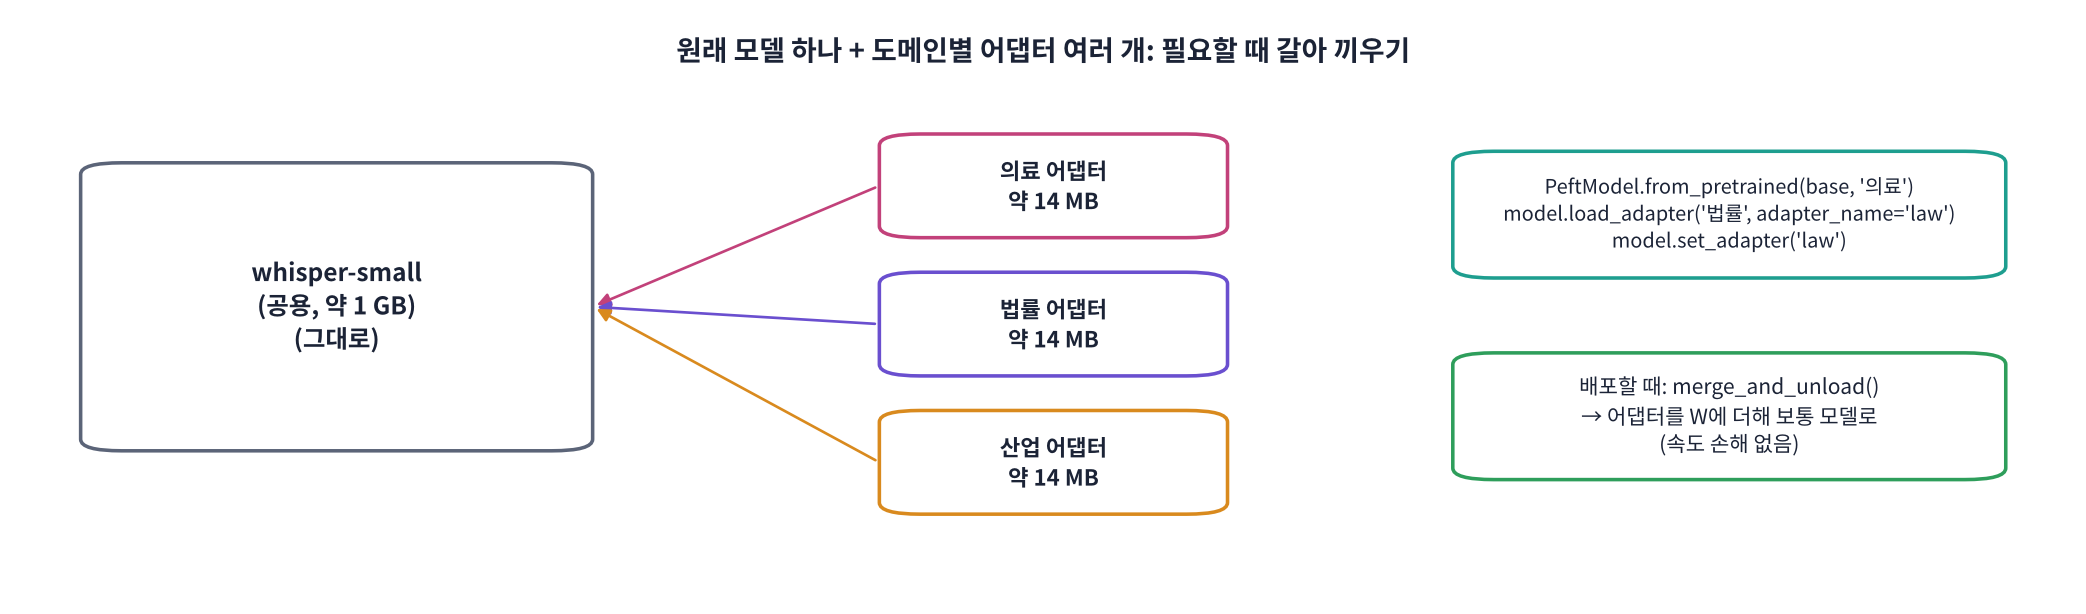

> 🎬 **애니메이션 D13-8:** [어댑터 갈아 끼우기](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#adapters) — 의료 · 법률 · 산업 어댑터를 바꿔 끼우며 결과 비교

### 🧩 빈칸 실습 8: 어댑터 저장
PeftModel의 저장 함수는 Hugging Face 모델과 같은 이름입니다. **어댑터만** 저장됩니다.

In [ ]:
# 🧩 빈칸 실습 8
ADAPTER_DIR = f"lora-{EN}"
model.____(ADAPTER_DIR)                                                                  # 빈칸 8
processor.save_pretrained(ADAPTER_DIR)
!ls -la {ADAPTER_DIR}
size_mb = os.path.getsize(f"{ADAPTER_DIR}/adapter_model.safetensors") / 1024**2
full_mb = total_before * 4 / 1024**2
print(f"어댑터 {size_mb:.1f} MB  vs  모델 전체 약 {full_mb:.0f} MB  →  {100 * size_mb / full_mb:.1f}%")
check(os.path.exists(f"{ADAPTER_DIR}/adapter_config.json") and size_mb < full_mb / 10, hint="빈칸 8 = save_pretrained")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
model.save_pretrained(ADAPTER_DIR)
```

**해설**: `adapter_config.json`(r · alpha · target_modules · 원래 모델 이름)과 `adapter_model.safetensors`(B · A 값)만 저장됩니다. whisper-small LoRA r = 32면 약 14 MB로, 모델 전체(약 970 MB)의 1.5% 정도입니다. 어댑터를 쓰려면 **같은 원래 모델**이 필요합니다(설정 파일에 이름이 적혀 있음). D14에서 Hugging Face Hub에 올릴 때도 이 폴더를 올립니다.

</details>

### 🧩 빈칸 실습 9: 새로 불러와 병합하기
원래 모델을 다시 받고 어댑터를 붙인 뒤, **어댑터를 W에 더해 보통 Whisper로 합치는** PeftModel 함수를 부르세요.

In [ ]:
# 🧩 빈칸 실습 9
from peft import PeftModel

base = WhisperForConditionalGeneration.from_pretrained(CFG["model_name"])
lora_model = PeftModel.from_pretrained(base, ADAPTER_DIR)          # 원래 모델 + 어댑터
merged = lora_model.____()                                                              # 빈칸 9
merged.to(DEVICE)
print(type(merged).__name__, "· LoRA 층이 남아 있나?", any("lora" in n for n, _ in merged.named_parameters()))

pred_merged = transcribe(merged, dom_test)
print(f"병합 모델 용어 정확도 {term_accuracy(test_terms, pred_merged):.1f}%  (Part 6 LoRA: {RESULTS['③ LoRA']['term_acc']:.1f}%)")
check(type(merged).__name__ == "WhisperForConditionalGeneration" and not any("lora" in n for n, _ in merged.named_parameters()),
      hint="빈칸 9 = merge_and_unload")

<details>
<summary><b>🔑 정답 및 해설 보기 (클릭)</b></summary>

```python
merged = lora_model.merge_and_unload()
```

**해설**: `merge_and_unload()`는 각 행렬에 W ← W + (α / r)·B·A를 계산해 넣고 LoRA 층을 떼어 냅니다. 결과는 **보통 `WhisperForConditionalGeneration`** 이라 D8의 faster-whisper 변환, `pipeline` 등 기존 도구를 그대로 쓸 수 있고 **추론 속도 손해가 없습니다**. 대신 합친 뒤에는 어댑터를 갈아 끼울 수 없습니다. 병합 결과는 학습 직후 LoRA와 거의 같습니다(fp16 학습이면 아주 작은 차이가 날 수 있음). 여러 도메인을 오가려면 병합하지 않고 `load_adapter()` · `set_adapter()`로 바꿔 끼웁니다(아래).

</details>

In [ ]:
# 참고: 원래 모델 하나에 어댑터 여러 개 (다른 도메인 어댑터가 있을 때)
# lora_model.load_adapter("lora-legal", adapter_name="legal")
# lora_model.set_adapter("legal")        # 법률 어댑터로 전환
# lora_model.set_adapter("default")      # 처음 불러온(의료) 어댑터로 복귀
print("현재 어댑터:", lora_model.active_adapter, "· 목록:", list(lora_model.peft_config.keys()))

> 💾 **Colab 세션이 끝나면 사라집니다.** D14에서 비교 · Hub 업로드에 쓰려면 어댑터 폴더(수십 MB)를 Google Drive에 복사하세요.

In [ ]:
# from google.colab import drive
# drive.mount("/content/drive")
# !cp -r {ADAPTER_DIR} /content/drive/MyDrive/

## Part 8. (선택) 8-bit 양자화: 더 큰 모델을 작은 GPU에

> 💬 **쉽게 말하면**: D8에서 배운 양자화를 **학습 쪽**에 씁니다. 가중치를 8-bit(1바이트)로 불러오면 메모리가 fp32의 1/4이 됩니다. 얼린 W는 8-bit로, 학습하는 LoRA만 정밀하게 두는 방식이 **QLoRA(4-bit) · 8-bit LoRA** 입니다. whisper-medium · large도 T4에서 LoRA 학습이 가능해집니다.

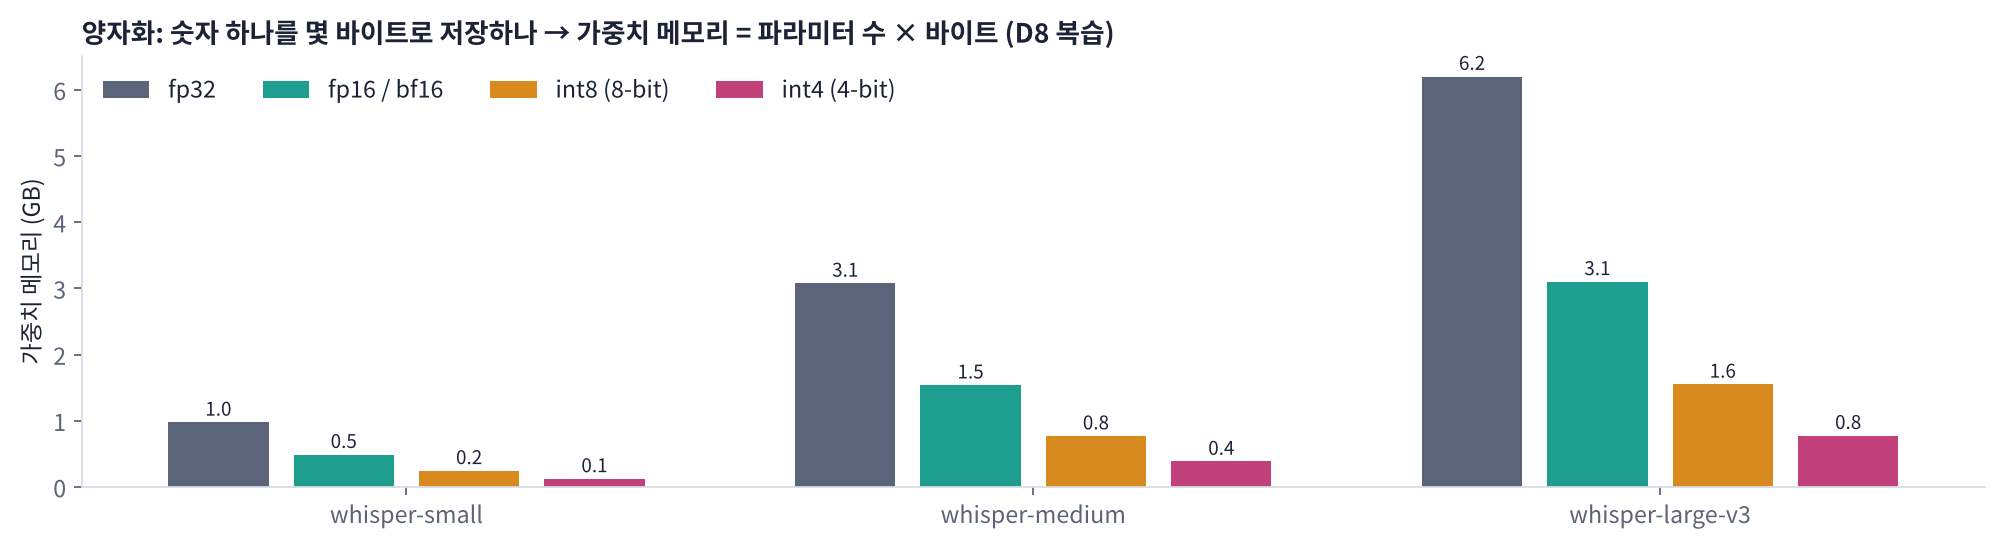

> ⚠️ `bitsandbytes`는 GPU(CUDA) 버전과 맞아야 해서 환경에 따라 설치가 실패할 수 있습니다. 그래서 **선택 실습**으로 두고 `USE_8BIT = True`일 때만 실행합니다. 실패해도 오늘 실습에는 영향이 없습니다.

> 🎬 **애니메이션 D13-9:** [양자화와 메모리](https://imguru-mooc.github.io/AI_Voice/day13/animation.html#quant) — fp32 · fp16 · 8-bit · 4-bit 가중치 메모리

In [ ]:
USE_8BIT = False                      # True로 바꾸면 whisper-medium을 8-bit로 불러와 메모리 비교 (약 1.5 GB 다운로드)
if USE_8BIT and GPU:
    try:
        !pip install -q -c colab_constraints.txt bitsandbytes
        from transformers import BitsAndBytesConfig
        m8 = WhisperForConditionalGeneration.from_pretrained("openai/whisper-medium",
                 quantization_config=BitsAndBytesConfig(load_in_8bit=True), device_map="auto")
        print(f"whisper-medium 8-bit 메모리: {m8.get_memory_footprint() / 1024**3:.2f} GB (fp32라면 약 3.1 GB)")
        from peft import prepare_model_for_kbit_training
        m8 = get_peft_model(prepare_model_for_kbit_training(m8), LoraConfig(r=32, lora_alpha=64, target_modules=["q_proj", "v_proj"], lora_dropout=0.05))
        m8.print_trainable_parameters()
        print("→ 이 모델도 Part 5와 같은 Trainer로 학습할 수 있습니다 (시간은 small의 약 3배)")
    except Exception as e:
        print("8-bit 실습을 건너뜁니다:", type(e).__name__, str(e)[:200])
else:
    print("USE_8BIT = False → 건너뜀 (선택 실습)")

---
### 📝 4교시 마무리: 개념 워크시트 · 제출

> **[worksheet.html 열기 → 4교시 탭](https://imguru-mooc.github.io/AI_Voice/day13/worksheet.html)** — 네 가지 비교 읽기, 원래 실력 확인(일반 CER), 처음 보는 용어의 한계, 어댑터 저장 파일, PeftModel.from_pretrained, merge_and_unload, 어댑터 갈아 끼우기, 8-bit · QLoRA
>
> 10문항을 풀고 **채점하기**를 누르세요.

## Part 9. 정리 & 과제

### 오늘 배운 것
| 개념 | 한 줄 정리 | 코드 |
|---|---|---|
| PEFT · LoRA | W는 얼리고 작은 B · A만 학습, 출력 = W·x + (α/r)·B·A·x | `LoraConfig(r=32, lora_alpha=64, ...)` |
| B = 0 초기화 | 학습 시작 때 원래 모델과 같음 | `np.zeros((d_out, r))` |
| 학습 파라미터 | whisper-small q · v에 r = 32 → 약 1.5% | `model.print_trainable_parameters()` |
| 도메인 데이터 | 용어 × 문장 틀, 시험은 처음 보는 틀, 증강 · replay | `TEMPLATES[:7]` / `TEMPLATES[7:]` |
| 용어 정확도 | 용어가 결과에 그대로 있는 비율 | `normalize(t) in normalize(p)` |
| 프롬프트 | 학습 없이 용어 힌트 | `processor.get_prompt_ids(PROMPT)` |
| LoRA 붙이기 | 한 줄 | `get_peft_model(model, lora_cfg)` |
| LoRA 학습 | lr 1e-3, label_names | `Seq2SeqTrainer(...)` |
| 어댑터 | 저장 · 불러오기 · 끄기 · 병합 | `save_pretrained`, `PeftModel.from_pretrained`, `disable_adapter`, `merge_and_unload` |
| 8-bit | 가중치 메모리 1/4 | `BitsAndBytesConfig(load_in_8bit=True)` |

### 📝 과제
1. **r 실험**: `CFG["r"]`을 8과 64로 바꿔 학습하고(alpha = 2r), 학습 파라미터 수 · 어댑터 크기 · 용어 정확도 · 일반 CER을 표로 비교하세요.
2. **다른 도메인**: 다른 도메인 하나로 어댑터를 하나 더 만들고, `load_adapter` · `set_adapter`로 두 어댑터를 바꿔 끼우며 서로의 시험 문장에서 결과를 비교하세요(의료 어댑터로 법률 문장을 받아쓰면?).
3. **(중요) 사람 목소리 시험**: 시험 문장 10개를 직접 녹음해 ① 원래 ② 프롬프트 ③ LoRA로 받아쓰고, gTTS 시험 결과와 얼마나 다른지 정리하세요.

### ✅ 개념 워크시트 제출
4교시 탭까지 모두 채점했다면 오늘 내용을 정리해 제출합니다.

> 📝 **[D13 개념 워크시트 열기](https://imguru-mooc.github.io/AI_Voice/day13/worksheet.html)** — 4교시 × 10문항 (객관식 5 · OX 2 · 선잇기 1 · 순서 맞추기 1 · 모두 고르기 1)

**제출 방법 (노션)**
1. 4개 교시 탭을 모두 채점합니다.
2. **제출** 버튼을 눌러 오답 정리를 엽니다.
3. **📋 캡처 (노션용 복사)**를 누른 뒤, 노션 제출 페이지에서 `Ctrl + V`로 붙여 넣습니다. **Part 6의 네 가지 비교 표**도 함께 붙이세요.

> 🎬 복습용: [애니메이션 전체 보기](https://imguru-mooc.github.io/AI_Voice/day13/animation.html) — D13-1 ~ D13-9

### 다음 시간 (D14)
**성능 비교 & 상용 API**: D12 Full 모델 · D13 LoRA 어댑터 · 원래 Whisper를 **같은 시험 세트**로 비교하고, OpenAI · Google · CLOVA Speech 같은 **상용 API**와 정확도 · 속도 · 비용을 벤치마크합니다. 마지막으로 만든 모델 · 어댑터를 **Hugging Face Hub에 업로드**합니다. D12 모델 · D13 어댑터를 Drive에 꼭 저장해 오세요.